In [1]:
"""Showcase a PMF-based Brownian coagulation example.

Builds a lognormal PMF aerosol, configures Brownian coagulation with
``distribution_type="discrete"``, runs a short guarded step, and plots PMF
concentration before/after execution to visualize redistribution. Designed
for quick execution with a small grid and modest sub-steps.

Example:
    Run the script to generate before/after concentration curves for a
    discrete PMF aerosol using the public ``par.dynamics`` API.
"""

'Showcase a PMF-based Brownian coagulation example.\n\nBuilds a lognormal PMF aerosol, configures Brownian coagulation with\n``distribution_type="discrete"``, runs a short guarded step, and plots PMF\nconcentration before/after execution to visualize redistribution. Designed\nfor quick execution with a small grid and modest sub-steps.\n\nExample:\n    Run the script to generate before/after concentration curves for a\n    discrete PMF aerosol using the public ``par.dynamics`` API.\n'

# Coagulation Pattern 1: PMF

Brownian coagulation using the public `par.dynamics` API with a
discrete/PMF representation:

1. Build a Brownian coagulation strategy with
   `distribution_type="discrete"`.
2. Wrap it in `par.dynamics.Coagulation`.
3. Run a short, fast step on a PMF aerosol and visualize the change.

In [2]:
# In Colab uncomment the following command to install particula:
# Use the v0.3.0 development checkout: `python -m pip install -e ".[extra]"`
import matplotlib.pyplot as plt
import numpy as np
import particula as par

## Build a PMF aerosol

We create a modest lognormal PMF and combine it with a native ambient environment.

In [3]:
# Radius bins (log-spaced, extended to 10 microns for visibility)
radius_bins = np.logspace(-8, -5, 150)  # m (10 nm to 10 um)

# Lognormal PMF (concentration per bin) - higher concentration for visible change
concentration_pmf = par.particles.get_lognormal_pmf_distribution(
    x_values=radius_bins,
    mode=np.array([80e-9]),
    geometric_standard_deviation=np.array([1.5]),
    number_of_particles=np.array(
        [1e10]
    ),  # m^-3 total (increased for visibility)
)

# Native ambient environment. GasData requires a species axis, so a
# zero-concentration, non-partitioning carrier fills that axis. Coagulation
# does not consume it; ambient pressure is specified independently.
environment = par.gas.EnvironmentData(
    temperature=np.array([298.15]),
    pressure=np.array([101325.0]),
    saturation_ratio=np.zeros((1, 1)),
)
gas = par.gas.GasData(
    name=["carrier"],
    molar_mass=np.array([0.02897]),
    partitioning=np.array([False]),
    concentration=np.zeros((1, 1)),
)
particles_pmf = par.particles.create_particle_data_from_radii(
    radii=radius_bins,
    concentration=concentration_pmf,
    distribution_type="discrete",
    density=1000.0,
)
pmf_aerosol = par.Aerosol(
    particles=particles_pmf,
    gas=gas,
    environment=environment,
)

## Configure coagulation (discrete)

Use the Brownian builder with `distribution_type="discrete"`, then wrap in
the public `Coagulation` runnable.

In [4]:
coagulation_strategy = (
    par.dynamics.BrownianCoagulationBuilder()
    .set_distribution_type("discrete")
    .build()
)
coagulation_process = par.dynamics.Coagulation(
    coagulation_strategy=coagulation_strategy
)

print(coagulation_process)

## Execute a short coagulation step

Keep the time step and sub-steps small for quick execution. The runnable
updates the aerosol in-place and returns it.

In [5]:
# Set up time and sub-steps for the coagulation process
# Longer time span for visible coagulation effect
time_step = 3600  # 1 hour per step
sub_steps = 100

radii = pmf_aerosol.particles.radii[0]
pmf_before = np.copy(pmf_aerosol.particles.concentration[0])

# Perform coagulation process for step 1
pmf_aerosol = coagulation_process.execute(
    pmf_aerosol, time_step=time_step, sub_steps=sub_steps
)
radii_after_step_1 = pmf_aerosol.particles.radii[0]
pmf_after_step_1 = np.copy(pmf_aerosol.particles.concentration[0])

# Perform coagulation process for step 2
pmf_aerosol = coagulation_process.execute(
    pmf_aerosol, time_step=time_step, sub_steps=sub_steps
)
radii_after_step_2 = pmf_aerosol.particles.radii[0]
pmf_after_step_2 = np.copy(pmf_aerosol.particles.concentration[0])

In [6]:
# Independently account for material mass; PDF values require radius integration.
bin_mass = 4.0 / 3.0 * np.pi * radius_bins**3 * 1000.0
mass_history = np.array(
    [
        np.sum(values * bin_mass)
        for values in (pmf_before, pmf_after_step_1, pmf_after_step_2)
    ]
)
print("Relative material mass drift:", mass_history / mass_history[0] - 1)
assert np.all(np.isfinite(pmf_after_step_2))
assert np.all(pmf_after_step_2 >= 0)

Relative material mass drift: [ 0.         -0.0011476  -0.00225778]


## Plot: concentration before/after

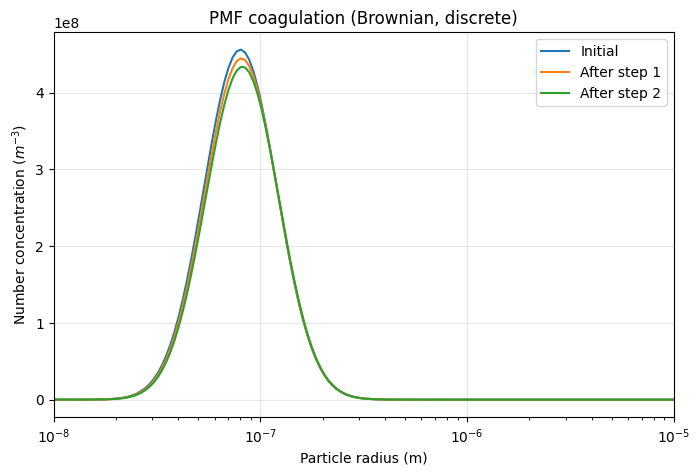

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(radii, pmf_before, label="Initial", color="tab:blue")
ax.plot(
    radii_after_step_1,
    pmf_after_step_1,
    label="After step 1",
    color="tab:orange",
)
ax.plot(
    radii_after_step_2,
    pmf_after_step_2,
    label="After step 2",
    color="tab:green",
)
ax.set_xscale("log")
ax.set_xlim(1e-8, 1e-5)  # 10 nm to 10 um
ax.set_xlabel("Particle radius (m)")
ax.set_ylabel(r"Number concentration ($m^{-3}$)")
ax.set_title("PMF coagulation (Brownian, discrete)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Native initialization and numerical limits

Native construction retains the explicitly generated concentration array.
Earlier versions used a preset builder that regenerated its default bimodal
distribution, replacing the declared inputs. The plots here therefore use
the stated mode and total number concentration, not that old preset result.
Finite-grid coagulation is not exactly mass conservative. Number loss and
distribution changes illustrate this workload; they are not a convergence
study or evidence of exact agreement between representations.

## Summary

- Strategy: `BrownianCoagulationBuilder().set_distribution_type("discrete")`
- Runnable: `par.dynamics.Coagulation`
- Representation: PMF (bin-based number concentration)
- Workload: 150 radius nodes, two one-hour calls with 100 substeps each